# Review of effectifs.csv (chronic conditions, French health insurance)

*https://www.data.gouv.fr/datasets/pathologies-effectif-de-patients-par-pathologie-sexe-classe-dage-et-territoire-departement-region*

Dataset: number of patients by condition (3 levels of detail), age group, sex and territory. 

We will conduct the cleaning and the exploration of the dataset to then present the results under a dashboard.

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/effectifs.csv"

## I - Cleaning

### 1. Extraction and reading
The file is ~1 GB, so loading takes a few seconds and needs several GB of memory.

In [57]:
df = pd.read_csv(path, sep=";", encoding="utf-8-sig")

In [58]:
print("Rows and columns:", df.shape)
df2 = df.copy()
df

Rows and columns: (5796000, 16)


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri
0,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,1,971,280.0,17040,1.643,"2,3",de 50 à 54 ans,femmes,48.0
1,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,3,999,50.0,6090,0.771,"2,3",de 50 à 54 ans,femmes,48.0
2,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,4,974,390.0,32630,1.205,"2,3",de 50 à 54 ans,femmes,48.0
3,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,77,350.0,48230,0.732,"2,3",de 50 à 54 ans,femmes,48.0
4,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,91,400.0,43370,0.927,"2,3",de 50 à 54 ans,femmes,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5795995,2024,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire actif,CAN_BPU_ACT,50-54,1,11,77,60.0,48020,0.121,3,de 50 à 54 ans,hommes,58.0
5795996,2024,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire actif,CAN_BPU_ACT,50-54,1,11,92,70.0,52200,0.125,3,de 50 à 54 ans,hommes,58.0
5795997,2024,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire actif,CAN_BPU_ACT,50-54,1,24,41,20.0,10600,0.142,3,de 50 à 54 ans,hommes,58.0
5795998,2024,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire actif,CAN_BPU_ACT,50-54,1,27,90,NaN,4350,NaN,3,de 50 à 54 ans,hommes,58.0


### 2. Variables

In [59]:
var = df.columns
var

Index(['annee', 'patho_niv1', 'patho_niv2', 'patho_niv3', 'top', 'cla_age_5',
       'sexe', 'region', 'dept', 'Ntop', 'Npop', 'prev', 'Niveau prioritaire',
       'libelle_classe_age', 'libelle_sexe', 'tri'],
      dtype='object')

In [60]:
# rename variables
df = df.rename(columns={
    "annee": "year", "patho_niv1": "patho_l1", "patho_niv2": "patho_l2", "patho_niv3": "patho_l3",
    "top": "patho_code", "cla_age_5": "age_gp", "sexe": "sex", "dept": "dep",
    "Ntop": "nb_patients", "Npop": "pop", "prev": "prev",
    "Niveau prioritaire": "priority_level", "libelle_classe_age": "age_label",
    "libelle_sexe": "sex_label", "tri": "sort_order",
})

In [61]:
var = df.columns
var

Index(['year', 'patho_l1', 'patho_l2', 'patho_l3', 'patho_code', 'age_gp',
       'sex', 'region', 'dep', 'nb_patients', 'pop', 'prev', 'priority_level',
       'age_label', 'sex_label', 'sort_order'],
      dtype='object')

| Variable | Meaning |
|---|---|
| `year` | Year (2015 to 2024) |
| `patho_l1` | pathology group, level 1 (broadest) |
| `patho_l2` | pathology sub-group, level 2 (empty = total of level 1, filled with `full` in section 4) |
| `patho_l3` | Detailed condition, level 3 (empty = total of level 2, filled with `full` in section 4) |
| `patho_code` | pathology code (unique) |
| `age_gp` | 5-year age group (`tsage` = all ages (renamed `All` in section 6.1)) |
| `sex` | 1 = men, 2 = women, 9 = both |
| `region` | Region code (`99` = all of France) |
| `dep` | Department code (`999` = region total) |
| `nb_patients` | Number of patients with the pathology (empty = masked, count too small) |
| `pop` | Population of the group |
| `prev` | Prevalence in % (about `nb_patients / pop * 100`) -> to compare groups of different sizes |
| `priority_level` | Priority level given by the provider (to confirm in the documentation) |
| `age_label` | Age class according to `age_gp` (encoded) |
| `sex_label` | Sex class according to `sex` (encoded) |
| `sort_order` | Sort order of the provider |

### 3. Data types

In [62]:
df.dtypes

year                int64
patho_l1           object
patho_l2           object
patho_l3           object
patho_code         object
age_gp             object
sex                 int64
region              int64
dep                object
nb_patients       float64
pop                 int64
prev              float64
priority_level     object
age_label          object
sex_label          object
sort_order        float64
dtype: object

### 4. Missing values and duplicates

In [63]:
missing = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(1) # pourcentage of missing value
pd.DataFrame({"missing": missing, "missing_%": missing_pct})

,missing,missing_%
year,0,0.0
patho_l1,0,0.0
patho_l2,604800,10.4
patho_l3,1310400,22.6
patho_code,0,0.0
age_gp,0,0.0
sex,0,0.0
region,0,0.0
dep,0,0.0
nb_patients,1526386,26.3


There are 3 kinds of missing values, with 3 different causes.

| Columns | Missing | Cause | Treatment |
|---|---|---|---|
| `patho_l2`, `patho_l3` | 10.4 % and 22.6 % | **Structural missing:** the row is a total of the level above, so there is nothing to put at the lower level. `patho_l3` is empty whenever `patho_l2` is empty (604,800 rows), so every level 1 total row is missing both. | Replaced by `"full"`: the category above is the last level of description for this observation (see section 6.2). |
| `nb_patients`, `prev` | 26.3 % | **Masked by the provider:** small counts are hidden to protect confidentiality (the smallest published value is 10). `pop` is always known. | Kept as missing, not imputed. A flag `is_masked` marks these rows. |
| `priority_level`, `sort_order` | 1.3 % | Same 75,600 rows, all `POP_TOT_IND` (total population, not a pathology). | Left as is: these columns are not used in the analysis. |

**Why we won't impute `nb_patients` and `prev`:** the masked values are not missing at random, they are exactly the small ones. Replacing them with a mean or a model would overestimate them and invent numbers on the map.

**Treatment of the missing values**
- Structural missing values (`patho_l2`, `patho_l3`) are filled with `"full"`. A row with `patho_l2 = "full"` is a total of level 1 (explained in section 6.2).
- Masked values (`nb_patients`, `prev`) stay missing. We only add a flag to find them easily.

In [64]:
# Structural missing values: the row is a total, so the level above is the last level of description
df["patho_l2"] = df["patho_l2"].fillna("full")
df["patho_l3"] = df["patho_l3"].fillna("full")

# Masked values: True when the count was hidden by the provider (small number)
df["is_masked"] = df["nb_patients"].isna()
print("Masked rows (%):", round(df["is_masked"].mean() * 100, 1))

Masked rows (%): 26.3


In [65]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


### 5. Numeric variables
We look at the numbers first. The distribution of `prev` will show a problem to solve in the next section.

In [66]:
df[["nb_patients", "pop", "prev"]].describe()

,nb_patients,pop,prev
count,4.269614e+06,5.796000e+06,4.269614e+06
mean,5.560028e+03,1.036321e+05,6.204748e+00
std,1.593980e+05,9.929227e+05,1.593149e+01
min,1.000000e+01,1.000000e+01,0.000000e+00
25%,5.000000e+01,7.740000e+03,2.740000e-01
50%,2.000000e+02,1.709000e+04,9.790000e-01
75%,9.500000e+02,4.285000e+04,4.198000e+00
max,6.882340e+07,6.882340e+07,1.000000e+02


**`prev` is very asymmetric.**
- The median is **0.98 %**: half of the rows have a prevalence below 1 %. The 75th percentile is only **4.2 %**.
- The mean (**6.2 %**) is much higher than the median. A few very high values pull it up, so the mean is not representative here and the median should be preferred.
- This is expected: each row is a very small subgroup (one pathology, one age group, one sex, one department) and most pathologies affect a small share of the population.

**`nb_patients` and `pop`** have the same maximum (about 68.8 million): it is the total French population, on the same `POP_TOT_IND` rows. The minimum is 10, which matches the masking of small counts.

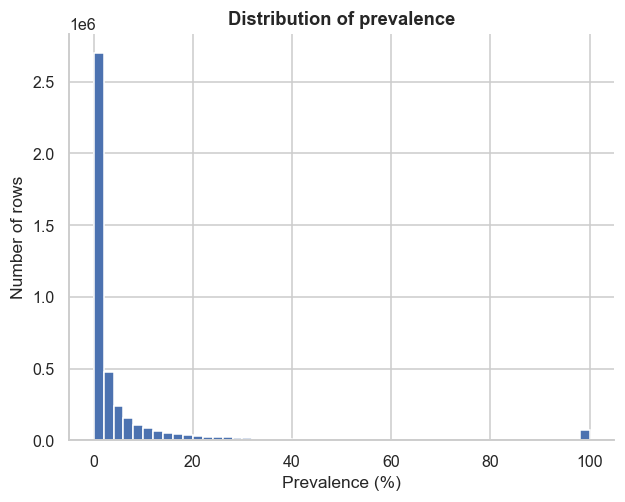

In [67]:
df["prev"].hist(bins=50)
plt.xlabel("Prevalence (%)")
plt.ylabel("Number of rows")
plt.title("Distribution of prevalence")
plt.show()

**The small peak at 100 %** must come from rows including the total population (where the prevalence is 100 % by definition). We will discuss this issue below in the categories part (6.2).


### 6. Categories
Goal of this section: know which rows can be used together without counting the same patients several times.

#### 6.1 Age and sex

In [68]:
# number of categories per variable
text_cols = df.select_dtypes(include="object").columns
df[text_cols].nunique()

patho_l1           18
patho_l2           49
patho_l3           62
patho_code         79
age_gp             21
dep               102
priority_level      5
age_label          21
sex_label           3
dtype: int64

In [69]:
# What are the age groups ?
print("Age groups:", sorted(df["age_gp"].unique()))


Age groups: ['00-04', '05-09', '10-14', '15-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85-89', '90-94', '95et+', 'tsage']


In [70]:
# sex codes
print("Sex codes:", df["sex"].unique())

Sex codes: [2 9 1]


- 1 : men
- 2 : women
- 9 : both (total)

In [71]:
# Test on a precise group the category 9 (diabetes, 2023, all ages, Paris)
test_gp = df[(df["year"] == 2023) & (df["patho_code"] == "DIA_CAT_CAT") & (df["age_gp"] == "tsage") & (df["dep"] == "75")]
print(test_gp[["sex", "nb_patients", "pop", "prev"]])

men_women = test_gp[test_gp["sex"] != 9]["nb_patients"].sum()
total = test_gp[test_gp["sex"] == 9]["nb_patients"].sum()

# results
print("Men + women:", men_women, " -> Total (9):", total)

         sex  nb_patients      pop   prev
2767273    1      56970.0   981260  5.806
2767357    9     101310.0  2070400  4.893
5062624    2      44340.0  1089130  4.071
Men + women: 101310.0  -> Total (9): 101310.0


The total of observations with sex 9 is the sum of observations with sex 1 and 2, as shown by the result for that specific group tested here.

In [72]:
# Cleaning on names for easier reading
df["age_gp"] = df["age_gp"].replace({"tsage": "All"})
df["dep"] = df["dep"].astype(str)

#### 6.2 Pathologies
The histogram of `prev` showed rows that are not pathologies (peak at 100 %). We will proceed in 4 steps:
1. Remove the rows that are not pathologies.
2. Understand the 3 levels of the pathology codes.
3. Build a readable name for each row from these 3 levels.
4. Keep one level to avoid double counting.

**Step 1: flag the rows that are not pathologies**

In [73]:
# get all codes of level 1 to know what to target
lvl1 = df[((df["patho_l2"] == "full") | (df["patho_l1"] == df["patho_l2"]))]
lvl1[["patho_l1", "patho_code"]].drop_duplicates().sort_values("patho_l1")

,patho_l1,patho_code
489877,Affections de longue durée (dont 31 et 32) pou...,ALD_CAT_CAT
384755,Cancers,CAN_CAT_CAT
11152,Diabète,DIA_CAT_CAT
62455,Hospitalisation pour Covid-19,INF_COV_HOS
35466,Hospitalisations hors pathologies repérées (av...,HHP_CAT_INC
37468,Insuffisance rénale chronique terminale,IRT_CAT_CAT
189954,Maladies cardioneurovasculaires,MCV_CAT_CAT
35369,Maladies du foie ou du pancréas (hors mucovisc...,MFP_CAT_EXC
88802,Maladies inflammatoires ou rares ou infection VIH,IRV_CAT_CAT
3474,Maladies neurologiques,NEU_CAT_CAT


The categories that are not about a pathology are the following:
- `POP_` = total population -> it explains the 100% seen above on the prevalence data
- `HHP_`= hospitalizations outside identified conditions

Thus, we need to create a flag to be able to make the distinction between them and pathologies.

In [74]:
# "~" inverts the result: is_patho is True for real pathologies
df["is_patho"] = ~df["patho_code"].str.startswith(("POP_", "HHP_"))
print(df["is_patho"].value_counts())

is_patho
True     5569200
False     226800
Name: count, dtype: int64


`is_patho` is `False` for the codes starting with `POP_` (total population) and `HHP_` (hospitalizations outside identified conditions). They are references, not pathologies. For example `POP_TOT_IND` is the total of people who used care, so its prevalence is 100 % by definition (the peak in the histogram).

We keep these rows in the dataset and filter them with `is_patho` when needed (rankings, averages).

**Step 2: understand the 3 levels**

Each code has 3 blocks, `FAMILY_SUBGROUP_DETAIL`, which match the columns `patho_l1`, `patho_l2` and `patho_l3`. `CAT` means "category": a total, with no more detail at this level.

Example: `CAN_CAT_CAT` is the total of **all cancers**.
- `CAN` = cancers (level 1)
- `CAT` = no sub-group (level 2 is `full`)
- `CAT` = no detail (level 3 is `full`)

So a line with `patho_l2 = "full"` stops at level 1. A line where `patho_l2` is filled but `patho_l3 = "full"` is the total of one sub-group. A line with `patho_l3` filled is the most detailed one.

In [75]:
# The cancer family as an example: one row per code with its 3 levels
cancers = df[df["patho_l1"] == "Cancers"][["patho_code", "patho_l1", "patho_l2", "patho_l3"]].drop_duplicates()
cancers

,patho_code,patho_l1,patho_l2,patho_l3
10010,CAN_SEI_SUR,Cancers,Cancer du sein de la femme,Cancer du sein de la femme sous surveillance
208046,CAN_BPU_CAT,Cancers,Cancer bronchopulmonaire,full
209806,CAN_BPU_ACT,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire actif
218743,CAN_BPU_SUR,Cancers,Cancer bronchopulmonaire,Cancer bronchopulmonaire sous surveillance
220890,CAN_CRE_SUR,Cancers,Cancer colorectal,Cancer colorectal sous surveillance
221913,CAN_PRO_CAT,Cancers,Cancer de la prostate,full
223616,CAN_PRO_ACT,Cancers,Cancer de la prostate,Cancer de la prostate actif
224031,CAN_AUT_ACT,Cancers,Autres cancers,Autres cancers actifs
326160,CAN_PRO_SUR,Cancers,Cancer de la prostate,Cancer de la prostate sous surveillance
327847,CAN_SEI_CAT,Cancers,Cancer du sein de la femme,full


In [76]:
# other example with diabetes
diabete = df[df["patho_l1"] == "Diabète"][["patho_code", "patho_l1", "patho_l2", "patho_l3"]].drop_duplicates()
diabete

,patho_code,patho_l1,patho_l2,patho_l3
11152,DIA_CAT_CAT,Diabète,Diabète,Diabète


Some categories only have one level like `Diabète`.

**Step 3: build a readable name for each row**

The codes (`CAN_CAT_CAT`...) are not readable in a chart. The 3 level columns already contain the names, so we build one column `patho_label` from them instead of writing a dictionary by hand. We keep the names in French as in the file (only the interface of the dashboard is in English).

The label is the most precise level that is useful:
- `patho_l2 = "full"`: the row is a level 1 total, the label is `patho_l1`.
- `patho_l3` is `full` or the same as `patho_l2`: the label is `patho_l2`.
- otherwise the label is `patho_l3`.

In [77]:
# Start with the most detailed level, then replace it when there is nothing more precise
df["patho_label"] = df["patho_l3"]
same_as_l2 = (df["patho_l3"] == "full") | (df["patho_l3"] == df["patho_l2"]) # fusion
df.loc[same_as_l2, "patho_label"] = df["patho_l2"]
df.loc[df["patho_l2"] == "full", "patho_label"] = df["patho_l1"]

# One row per code with its label (check)
df[["patho_code", "patho_label"]].drop_duplicates().sort_values("patho_code")

,patho_code,patho_label
489877,ALD_CAT_CAT,Affections de longue durée (dont 31 et 32) pou...
224031,CAN_AUT_ACT,Autres cancers actifs
386434,CAN_AUT_CAT,Autres cancers
470953,CAN_AUT_SUR,Autres cancers sous surveillance
209806,CAN_BPU_ACT,Cancer bronchopulmonaire actif
...,...,...
48578,TPS_ADR_EXC,Traitements antidépresseurs ou thymorégulateur...
51099,TPS_ANX_EXC,Traitements anxiolytiques (hors pathologies)
46059,TPS_CAT_EXC,Traitements psychotropes (hors pathologies)
53696,TPS_HYP_EXC,Traitements hypnotiques (hors pathologies)


**Step 4: keep one level to avoid double counting**

A total and its details count the same patients (all cancers = breast + prostate + ...). If we mix levels in one sum or one chart, patients are counted several times. For an overview, we use only the level 1 totals.

In [78]:
# Level 1 rows = total of a family (no sub-level)
# Either l2 is "full", or l2 has the same name as l1 (families with no deeper detail)
lvl1 = df[df["is_patho"] & ((df["patho_l2"] == "full") | (df["patho_l1"] == df["patho_l2"]))]

# All level 1 codes
lvl1[["patho_l1", "patho_code"]].drop_duplicates().sort_values("patho_l1")

,patho_l1,patho_code
489877,Affections de longue durée (dont 31 et 32) pou...,ALD_CAT_CAT
384755,Cancers,CAN_CAT_CAT
11152,Diabète,DIA_CAT_CAT
62455,Hospitalisation pour Covid-19,INF_COV_HOS
37468,Insuffisance rénale chronique terminale,IRT_CAT_CAT
189954,Maladies cardioneurovasculaires,MCV_CAT_CAT
35369,Maladies du foie ou du pancréas (hors mucovisc...,MFP_CAT_EXC
88802,Maladies inflammatoires ou rares ou infection VIH,IRV_CAT_CAT
3474,Maladies neurologiques,NEU_CAT_CAT
92396,Maladies psychiatriques,PSY_CAT_CAT


### 7. Geography
The file also contains total rows (all of France, all ages, both sexes...). If we add everything, patients are counted several times. So we filter first:
France only (`region == 99`), all ages (`All`), both sexes (`9`) and level 1 totals (`patho_l2 == "full"`).

In [79]:
print("Regions:", df["region"].nunique())
print("Departments:", df["dep"].nunique())
print("Missing region:", df["region"].isna().sum(), "& missing department:", df["dep"].isna().sum())

Regions: 19
Departments: 102
Missing region: 0 & missing department: 0


In [80]:
# Regions and departments
display(df["region"].value_counts())
display(df["dep"].value_counts())

region
76    676200
75    627900
84    627900
44    531300
11    434700
27    434700
24    338100
93    338100
28    289800
32    289800
52    289800
53    241500
94    144900
2      96600
6      96600
1      96600
3      96600
4      96600
99     48300
Name: count, dtype: int64

dep
999    917700
45      48300
18      48300
09      48300
32      48300
        ...  
63      48300
43      48300
42      48300
03      48300
04      48300
Name: count, Length: 102, dtype: int64

- `region == 99`: all of France
- `dep == "999"`: total of a region

In [81]:
# Flag for the geographic level of each row
df["geo_level"] = "Department"
df.loc[df["dep"] == "999", "geo_level"] = "Region"
df.loc[df["region"] == 99, "geo_level"] = "France"
print(df["geo_level"].value_counts())

geo_level
Department    4878300
Region         869400
France          48300
Name: count, dtype: int64


**`geo_level`**: `France`, `Region` or `Department`. France and region rows are totals of the departments below them. Mixing the levels in one sum counts the same patients several times.

### 8. Time

In [82]:
print("Years:", df["year"].unique().tolist())
print("Rows per year:")
df["year"].value_counts().sort_index()

Years: [2020, 2024, 2018, 2015, 2016, 2017, 2019, 2022, 2023, 2021]
Rows per year:


year
2015    579600
2016    579600
2017    579600
2018    579600
2019    579600
2020    579600
2021    579600
2022    579600
2023    579600
2024    579600
Name: count, dtype: int64

### 9. Summary

In [83]:
summary = {
    "rows": len(df),
    "columns": df.shape[1],
    "years": f"{df['year'].min()} to {df['year'].max()}",
    "regions": df["region"].nunique(),
    "departments": df["dep"].nunique(),
    "condition groups": df["patho_l1"].nunique(),
    "missing values (%)": round(df.isna().mean().mean() * 100, 1),
    "duplicated rows": int(df.duplicated().sum()),
}
pd.Series(summary)

rows                       5796000
columns                         20
years                 2015 to 2024
regions                         19
departments                    102
condition groups                18
missing values (%)             2.8
duplicated rows                  0
dtype: object

In [84]:
# save the clean version of the csv
df.to_csv("../data/effectifs_clean.csv")

### Data cleaning summary

The dataset is ready for exploration, with clear rules for interpretation:

- **Missing values:** structural gaps were labelled `"full"`. Confidential counts remain missing and are flagged with `is_masked`. Imputation would distort small counts.
- **Double counting:** age, sex, geography and pathology totals overlap with detailed rows. Each comparison must use consistent levels.
- **Category types:** `is_patho` separates population and hospitalization references from the other categories. Treatment-only categories still require separate interpretation.
- **Readability:** `patho_label` and `geo_level` make filtering and dashboard navigation easier.

## II - Exploration

Part I cleaned the file and explained its structure. 
Part II reads and understands patterns in the dataset, starting from the national level, down to the regions and to sub-categories.

### 1. What the dataset is made of

Before any figure: how many codes exist at each level and of which type of care. This decides
what can be compared with what.

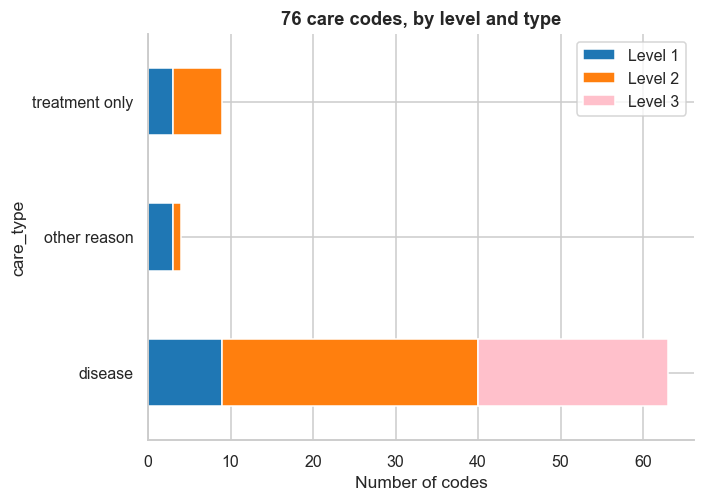

,Level 1,Level 2,Level 3
care_type,,,
disease,9,31,23
other reason,3,1,0
treatment only,3,6,0


In [104]:
# Part I did not describe the codes themselves, so we do it here: one row per care code
codes = df[df["is_patho"]].drop_duplicates("patho_code").copy()
codes = codes[["patho_code", "patho_l1", "patho_l2", "patho_l3", "patho_label"]]

# a code has no level below it when the lower column is "full" or repeats the one above
no_level_2 = (codes["patho_l2"] == "full") | (codes["patho_l2"] == codes["patho_l1"])
no_level_3 = (codes["patho_l3"] == "full") | (codes["patho_l3"] == codes["patho_l2"])
codes["level"] = 3
codes.loc[no_level_3, "level"] = 2
codes.loc[no_level_2, "level"] = 1   # last, so it wins over level 2

# type of care, read from the first letters of the code (see the code table in part I)
codes["care_type"] = "disease"
codes.loc[codes["patho_code"].str.startswith(("TFC_", "TPS_", "TAA_")), "care_type"] = "treatment only"
codes.loc[codes["patho_code"].str.startswith(("MAT_", "INF_", "ALD_")), "care_type"] = "other reason"

counts = pd.crosstab(codes["care_type"], codes["level"])
counts.columns = ["Level 1", "Level 2", "Level 3"]
counts.columns.name = None

counts.plot(kind="barh", stacked=True, color=["tab:blue", "tab:orange", "pink"])
plt.xlabel("Number of codes")
plt.title(f"{len(codes)} care codes, by level and type")
plt.show()

display(counts)

A level 1 code is the total of a category, a level 2 code the total of a sub-group and a level 3 code details. A total and its details count the same patients. 

Section 5 tests what level of information is needed in the analysis.

### 2. The national picture
This part will answer 3 questions :
- Which categories are the most frequent ? 
- How have they changed over ten years ?
- Who is concerned ?

#### *Which categories are the most frequent ?*

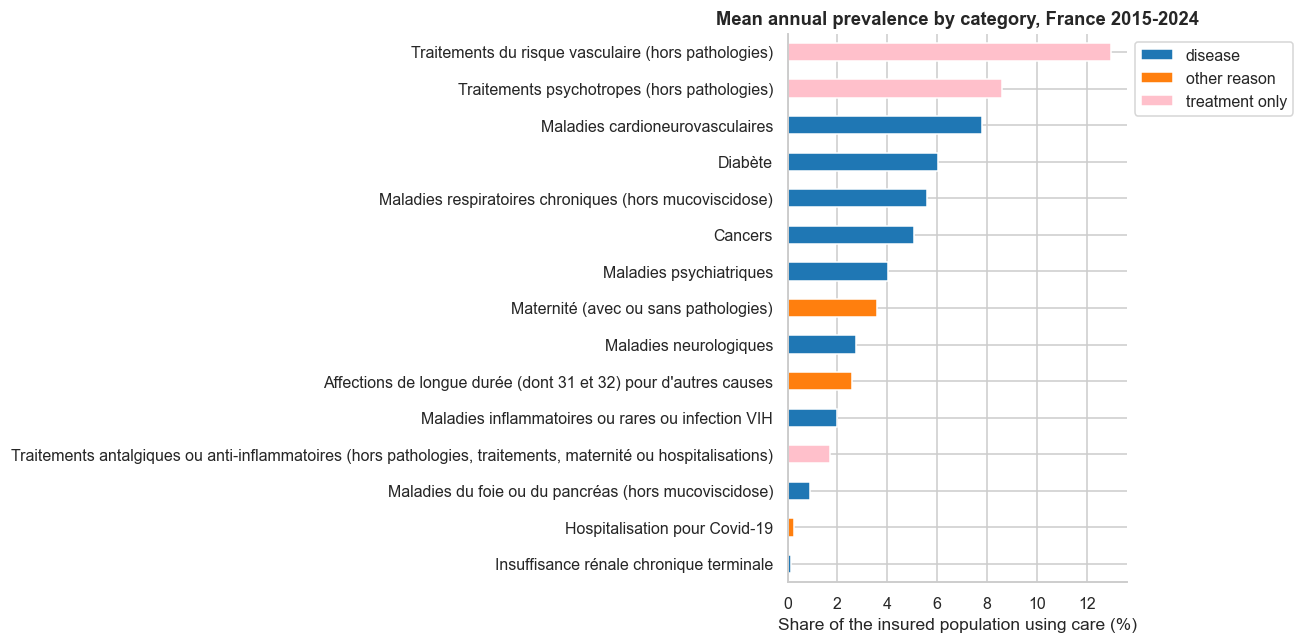

In [105]:
# national reference: France, all ages, both sexes, real pathologies only
france = df[(df["geo_level"] == "France") & (df["age_gp"] == "All") & (df["sex"] == 9) & df["is_patho"]]
france = france.merge(codes[["patho_code", "level", "care_type"]], on="patho_code")
level1 = france[france["level"] == 1]

last_year = df["year"].max()
first_year = df["year"].min()

# mean prevalence of each category over the whole period
ranking = level1.groupby("patho_label")["prev"].mean().sort_values()

# same values split by type of care, to color the bars
by_type = level1.groupby(["patho_label", "care_type"])["prev"].mean().unstack(fill_value=0)
by_type.columns.name = None

by_type.loc[ranking.index].plot(kind="barh", stacked=True, figsize=(12, 6),
                                color=["tab:blue", "tab:orange", "pink"])
plt.xlabel("Share of the insured population using care (%)")
plt.ylabel("")
plt.legend(bbox_to_anchor=(1, 1))
plt.title(f"Mean annual prevalence by category, France {first_year}-{last_year}")
plt.tight_layout()
plt.show()

The two categories with the highest prevalence are **not diseases**. These are: vascular-risk and psychotropic treatments delivered without an identified condition. 

For next steps, this will be taken into account to avoid any mixed pattern or signal.

#### *How did categories of level 1 change over ten years ?*

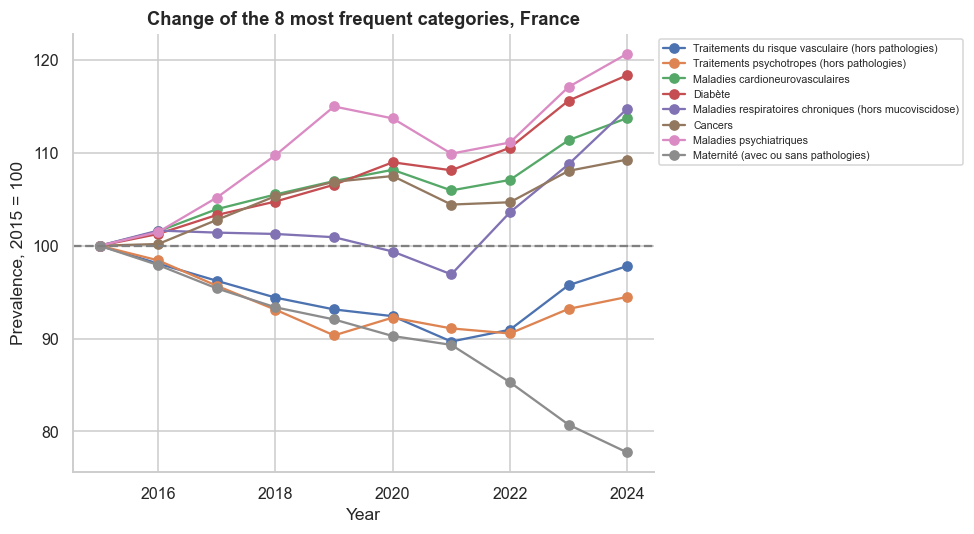

In [158]:
# index 100 on the first year, so categories with very different levels can be compared
trend = level1.pivot_table(index="year", columns="patho_label", values="prev")
biggest = ranking.sort_values(ascending=False).head(8).index
indexed = 100 * trend[biggest] / trend[biggest].iloc[0] # to compare the variation in %
indexed.columns.name = None

indexed.plot(marker="o", figsize=(9, 5))
plt.axhline(100, color="grey", linestyle="--")
plt.xlabel("Year")
plt.ylabel(f"Prevalence, {first_year} = 100")
plt.title("Change of the 8 most frequent categories, France")
plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

#### *What age range is concerned by which category ?*

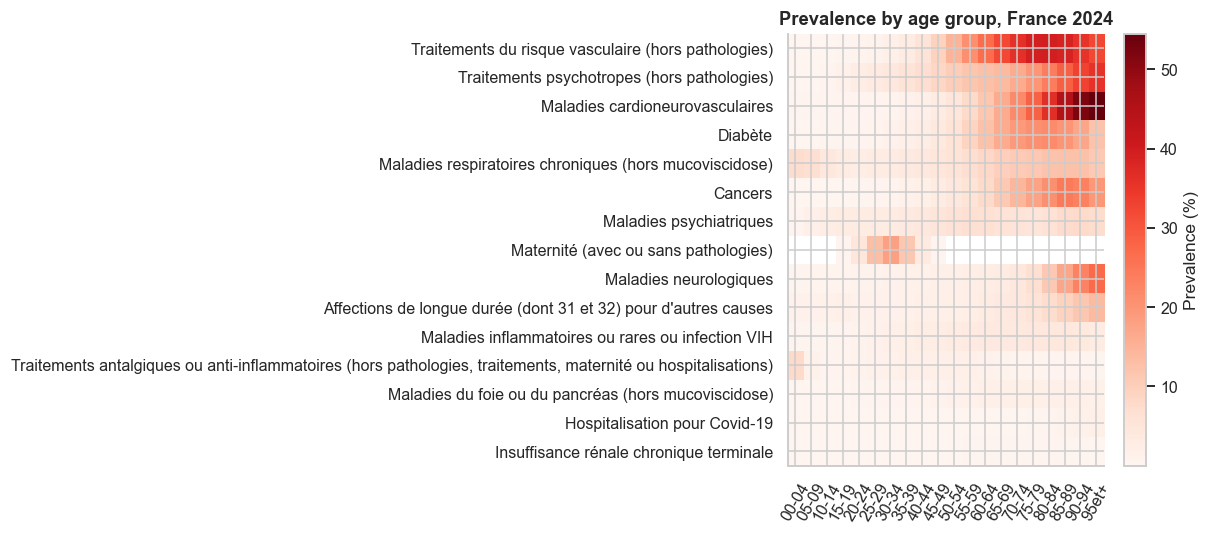

In [88]:
# France, one row per age group, latest year, level 1 categories
france_age = df[(df["geo_level"] == "France") & (df["age_gp"] != "All") & (df["sex"] == 9)
                & df["is_patho"] & (df["year"] == last_year)]
france_age = france_age.merge(codes[["patho_code", "level"]], on="patho_code")

heat = france_age[france_age["level"] == 1].pivot_table(index="patho_label", columns="age_gp", values="prev")
heat = heat.loc[ranking.sort_values(ascending=False).index]

plt.figure(figsize=(11, 5))
plt.imshow(heat, aspect="auto", cmap="Reds")
plt.xticks(range(len(heat.columns)), heat.columns, rotation=60)
plt.yticks(range(len(heat.index)), heat.index)
plt.colorbar(label="Prevalence (%)")
plt.title(f"Prevalence by age group, France {last_year}")
plt.tight_layout()
plt.show()

#### *Is there a difference between genders ? Is a gender more affected by a category ?*

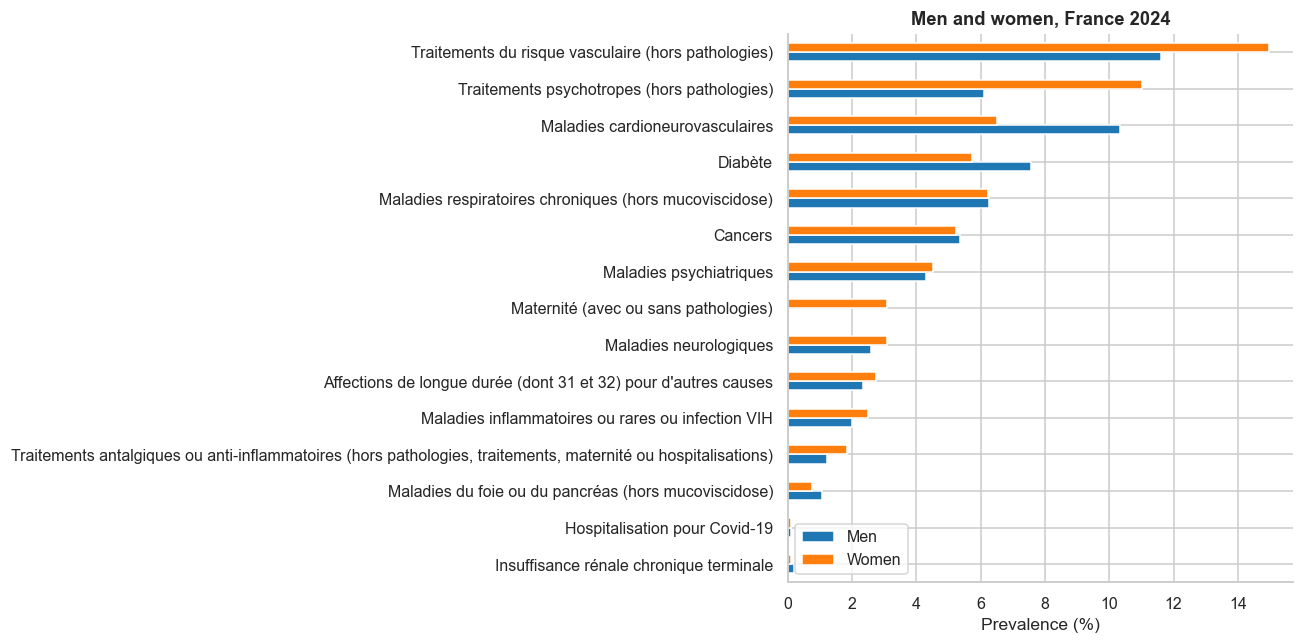

In [89]:
# France, latest year, one column per sex (1 = men, 2 = women)
sexes = df[(df["geo_level"] == "France") & (df["age_gp"] == "All") & df["sex"].isin([1, 2])
           & df["is_patho"] & (df["year"] == last_year)]
sexes = sexes.merge(codes[["patho_code", "level"]], on="patho_code")
sexes = sexes[sexes["level"] == 1].pivot_table(index="patho_label", columns="sex", values="prev")
sexes.columns = ["Men", "Women"]

sexes.reindex(ranking.index).plot(kind="barh", figsize=(12, 6), color=["tab:blue", "tab:orange"])
plt.xlabel("Prevalence (%)")
plt.ylabel("")
plt.title(f"Men and women, France {last_year}")
plt.tight_layout()
plt.show()

**Age** drives almost everything. 

The gap between **men** and **women** appears small outside maternity. Also, they are not displayed here, but specific cancers could be a difference here as prostate and breast cancer. However, for now we only focus on level 1, since the utility of other levels will be discussed later. 

### 3. Do territories have the same profile as the national one ?

Comparing regions with the national profile requires a ratio. It is computed by doing : **regional prevalence divided by the national prevalence of the same year**. Above 1 the category is recorded more often than in France.

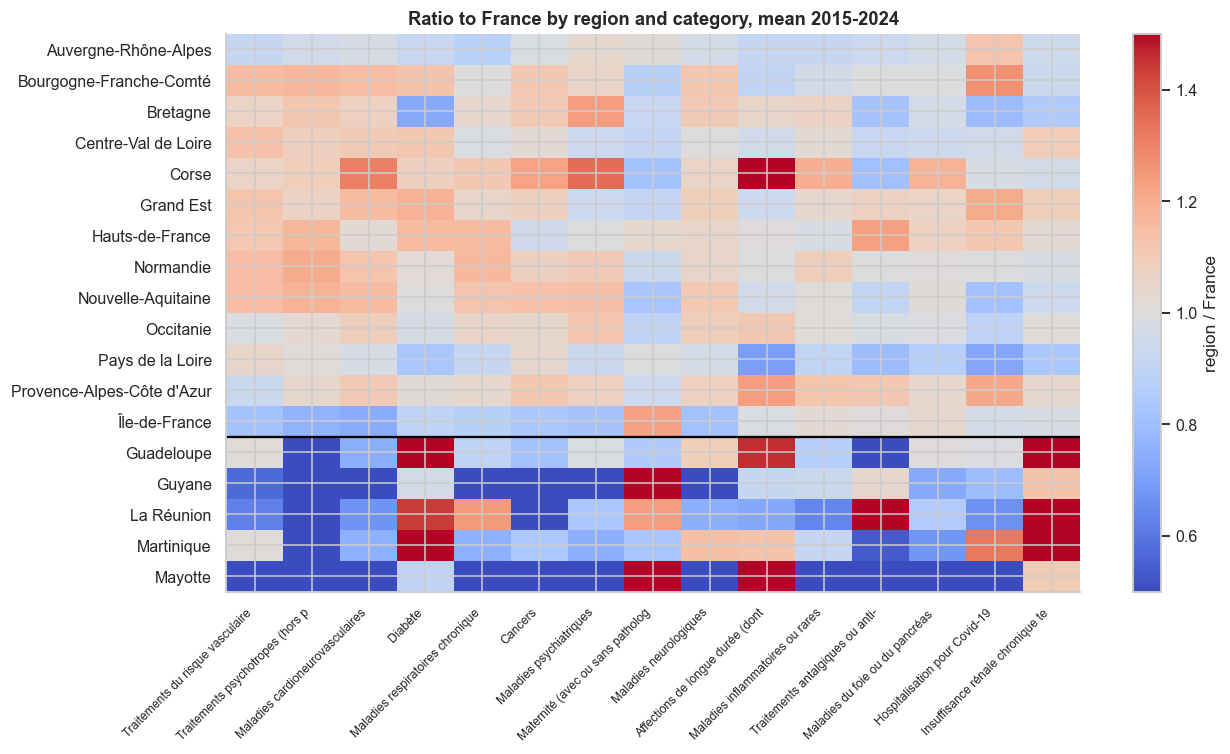

In [90]:
import json  # the region names are not in the dataset, they are read from the geojson

with open("../data/regions.geojson", encoding="utf-8") as f:
    geo = json.load(f)
region_names = {int(ft["properties"]["code"]): ft["properties"]["nom"] for ft in geo["features"]}

# regions, all ages, both sexes, level 1 categories
regions = df[(df["geo_level"] == "Region") & (df["age_gp"] == "All") & (df["sex"] == 9) & df["is_patho"]]
regions = regions.merge(codes[["patho_code", "level"]], on="patho_code")
regions = regions[regions["level"] == 1].copy()
regions["region_name"] = regions["region"].map(region_names)

# overseas regions are the ones with a code below 10
regions["area"] = "mainland"
regions.loc[regions["region"] < 10, "area"] = "overseas"

# ratio to France: regional prevalence divided by the national prevalence of the same year and code
national = level1[["year", "patho_code", "prev"]].rename(columns={"prev": "prev_france"})
regions = regions.merge(national, on=["year", "patho_code"])
regions["ratio"] = regions["prev"] / regions["prev_france"]

# one mean ratio per region and category, over the whole period
table = regions.groupby(["area", "region_name", "patho_label"])["ratio"].mean().unstack()
table = table[ranking.sort_values(ascending=False).index]

plt.figure(figsize=(12, 7))
plt.imshow(table, aspect="auto", cmap="coolwarm", vmin=0.5, vmax=1.5)
plt.xticks(range(len(table.columns)), [name[:32] for name in table.columns],
           rotation=45, ha="right", fontsize=8)
plt.yticks(range(len(table.index)), table.index.get_level_values("region_name"))
plt.axhline((table.index.get_level_values("area") == "mainland").sum() - 0.5, color="black")
plt.colorbar(label="region / France")
plt.title(f"Ratio to France by region and category, mean {first_year}-{last_year}")
plt.tight_layout()
plt.show()

The mainland rows are nearly uniform, except for Corse maybe, while the five overseas rows are not. **In overseas territories, some pathologies as cardiovascular ones or neurocardiovascular are less important than for the mainland**. Above, the heatmap about age and pathologies shows that these in particular are linked to age. Thus, to explain that **we can suppose that the age repartition is not the same in each territory**. For instance, Guyane and Mayotte may have more young people than the rest of the territory. 
This question will be discussed in the following steps.

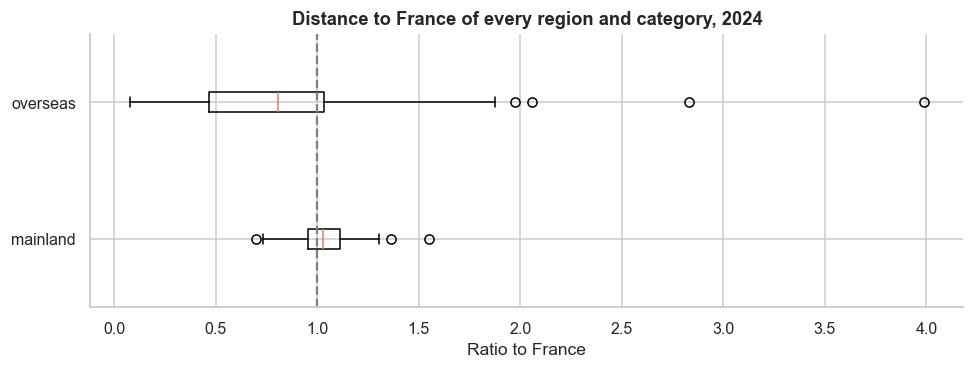

share of region-category pairs within 20 % of France:
area
mainland    94.9
overseas    36.0


In [91]:
# how far each region sits from France: all its ratios of the latest year, in one box per area
spread = regions[regions["year"] == last_year].dropna(subset=["ratio"])
groups = [spread.loc[spread["area"] == area, "ratio"] for area in ["mainland", "overseas"]]

plt.figure(figsize=(9, 3.5))
plt.boxplot(groups, tick_labels=["mainland", "overseas"], vert=False)
plt.axvline(1, color="grey", linestyle="--")
plt.xlabel("Ratio to France")
plt.title(f"Distance to France of every region and category, {last_year}")
plt.tight_layout()
plt.show()

inside = spread["ratio"].between(0.8, 1.25).groupby(spread["area"]).mean() * 100
print("share of region-category pairs within 20 % of France:")
print(inside.round(1).to_string())

Mainland is quite homogeneous while overseas regions are dispersing more, especially toward negative ratios, meaning that there is more under-representation. It shows in another way the important quantity of dark blue colors on the previous heat map.

### 4. Is the population really comparable between overseas and mainland ?

This part will discuss the questions raised above about age structure.

#### *Is the age structure similar ?*

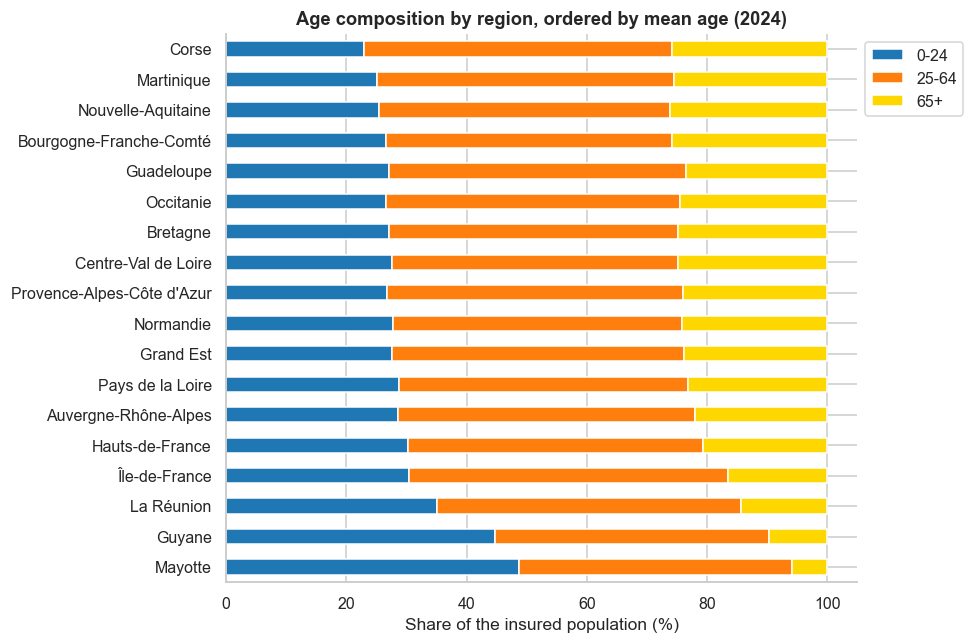

mean age by region:
region_name
Mayotte                       28.4
Guyane                        31.9
La Réunion                    37.5
Île-de-France                 39.3
Hauts-de-France               41.3
Auvergne-Rhône-Alpes          42.4
Pays de la Loire              42.9
Grand Est                     43.4
Normandie                     43.5
Provence-Alpes-Côte d'Azur    43.8
Centre-Val de Loire           44.0
Bretagne                      44.1
Occitanie                     44.2
Guadeloupe                    44.3
Bourgogne-Franche-Comté       44.7
Nouvelle-Aquitaine            45.2
Martinique                    45.6
Corse                         46.0


In [92]:
# the population is the same for every category, so one code is enough to read the age structure
one_code = codes.loc[codes["level"] == 1, "patho_code"].iloc[0]
pop = df[(df["geo_level"] == "Region") & (df["age_gp"] != "All") & (df["sex"] == 9)
         & (df["patho_code"] == one_code) & (df["year"] == last_year)][["region", "age_gp", "pop"]].copy()
pop["region_name"] = pop["region"].map(region_names)

# middle of each age group, read from its first number: 00-04 gives 2, 95et+ gives 97
pop["mid"] = pop["age_gp"].str.extract(r"(\d+)").astype(int) + 2

# mean age of each region, weighted by the population of each age group
mean_age = pop.groupby("region_name").apply(
    lambda g: (g["mid"] * g["pop"]).sum() / g["pop"].sum(), include_groups=False).sort_values()

# three age blocks, as a share of the regional population
pop["block"] = "25-64"
pop.loc[pop["mid"] < 25, "block"] = "0-24"
pop.loc[pop["mid"] >= 65, "block"] = "65+"
blocks = pop.groupby(["region_name", "block"])["pop"].sum().unstack()
blocks = 100 * blocks.div(blocks.sum(axis=1), axis=0)
blocks.columns.name = None

blocks.loc[mean_age.index].plot(kind="barh", stacked=True, figsize=(9, 6),
                                color=["tab:blue", "tab:orange", "gold"])
plt.xlabel("Share of the insured population (%)")
plt.ylabel("")
plt.title(f"Age composition by region, ordered by mean age ({last_year})")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print("mean age by region:")
print(mean_age.round(1).to_string())

A part of overseas population is younger, but this is not a generality. 3 out of the 5 regions (la Réunion, Guyane and Mayotte) have an age average smaller than the other regions. This indicates that performing an **age standardization against the national reference** is necessary before comparing these regions with France.

Without it, a lower raw prevalence in La Réunion, Guyane and Mayotte could simply reflect a younger population, since most pathologies become more frequent with age.

#### *Is the gap in age repartition due to maternity ?*

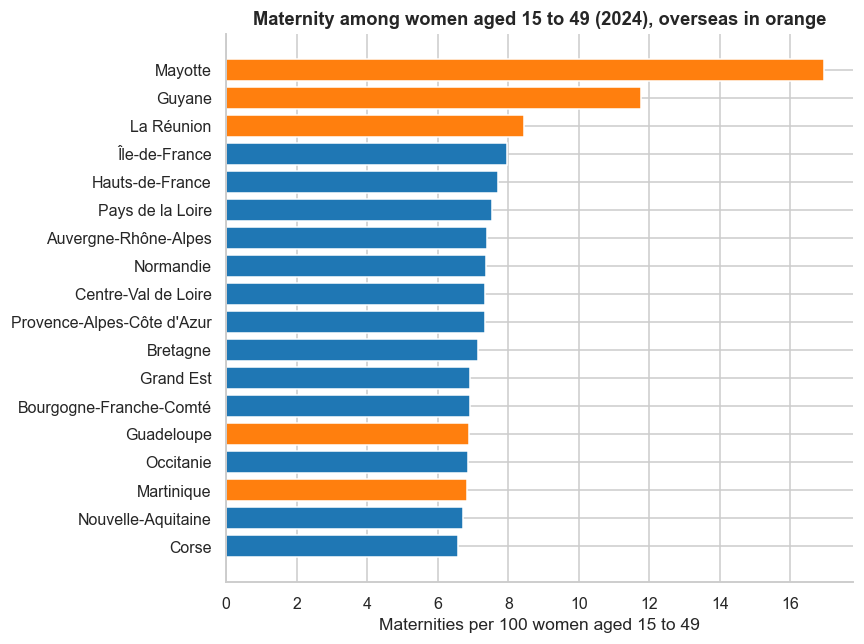

,region_name,area,women_share,rate_women
region,,,,
94,Corse,mainland,38.6,6.6
75,Nouvelle-Aquitaine,mainland,38.7,6.7
2,Martinique,overseas,36.6,6.8
76,Occitanie,mainland,40.1,6.9
1,Guadeloupe,overseas,38.1,6.9
27,Bourgogne-Franche-Comté,mainland,38.7,6.9
44,Grand Est,mainland,40.5,6.9
53,Bretagne,mainland,39.5,7.1
93,Provence-Alpes-Côte d'Azur,mainland,40.2,7.3


In [93]:
# maternity is counted on the whole population, so it mixes the birth rate with the
# share of women of childbearing age: dividing by those women separates the two
mat_code = codes.loc[codes["patho_label"].str.startswith("Maternit"), "patho_code"].iloc[0]

women = df[(df["geo_level"] == "Region") & (df["age_gp"] != "All") & (df["sex"] == 2)
           & (df["patho_code"] == mat_code) & (df["year"] == last_year)].copy()
women["mid"] = women["age_gp"].str.extract(r"(\d+)").astype(int) + 2
women = women[women["mid"].between(15, 49)]

# a region is dropped if one of its age groups is masked, a partial sum would understate the rate
mat = women.groupby("region").agg(
    mothers=("nb_patients", lambda s: s.sum() if s.notna().all() else float("nan")),
    women=("pop", "sum"))

# total population of the region, to get the share of women aged 15 to 49
total = df[(df["geo_level"] == "Region") & (df["age_gp"] == "All") & (df["sex"] == 9)
           & (df["patho_code"] == mat_code) & (df["year"] == last_year)].set_index("region")["pop"]

mat["women_share"] = 100 * mat["women"] / total
mat["rate_women"] = 100 * mat["mothers"] / mat["women"]
mat["region_name"] = mat.index.map(region_names)
mat["area"] = "mainland"
mat.loc[mat.index < 10, "area"] = "overseas"
mat = mat.sort_values("rate_women")

plt.figure(figsize=(8, 6))
plt.barh(mat["region_name"], mat["rate_women"],
         color=["tab:orange" if area == "overseas" else "tab:blue" for area in mat["area"]])
plt.xlabel("Maternities per 100 women aged 15 to 49")
plt.title(f"Maternity among women aged 15 to 49 ({last_year}), overseas in orange")
plt.tight_layout()
plt.show()

display(mat[["region_name", "area", "women_share", "rate_women"]].round(1))

As seen with the age graph, overseas is not one block. Three overseas regions have a high share of women of childbearing age (La Réunion, Guyane and Mayotte, from about 45 % to 52 % of the population), but Martinique and Guadeloupe have the lowest share of all regions. Having many young women does not mean having more births, which is why we look at the maternity rate per woman aged 15 to 49. Mayotte (17% of women) and Guyane (12%) are far above every mainland region. La Réunion (8%) is only slightly above Île-de-France and Martinique and Guadeloupe (about 7%) are at the lower end of the mainland range.

The relationship between age structure and maternity is partly circular: a high maternity rate produces a young population, which means more women of childbearing age, which in turn produces more maternities. With a single year, we cannot tell which one comes first. What the per-woman rate shows is that, once the structure is accounted for, a clearly higher rate remains in Mayotte and Guyane only. For these two regions, the young population is as much a consequence of the high maternity rate as a cause of the high prevalence.

Data on cost of living, average income, rate of moving toward mainland and education level would allow a deeper analysis. For now, the conclusion remains limited.

#### *What is the effect of standardizing for overseas regions?*

In [94]:
# Age standardization. Expected patients = national prevalence of each age group applied to
# the regional population of that age group. The ratio is then observed / expected.
wanted = codes.loc[codes["level"] <= 2, "patho_code"]
by_age = df[(df["age_gp"] != "All") & (df["sex"] == 9) & df["is_patho"] & df["patho_code"].isin(wanted)]

national_age = by_age[by_age["geo_level"] == "France"][["year", "patho_code", "age_gp", "prev"]]
national_age = national_age.rename(columns={"prev": "prev_france_age"})
region_age = by_age[by_age["geo_level"] == "Region"][
    ["year", "region", "patho_code", "age_gp", "nb_patients", "pop"]]

cells = region_age.merge(national_age, on=["year", "patho_code", "age_gp"])
cells["expected"] = cells["prev_france_age"] * cells["pop"] / 100

# a masked age group has no observed value, so it is removed from both sides
unmasked = cells["nb_patients"].notna()
cells["observed_kept"] = cells["nb_patients"].where(unmasked)
cells["expected_kept"] = cells["expected"].where(unmasked)

std = cells.groupby(["year", "region", "patho_code"], as_index=False).agg(
    observed=("observed_kept", "sum"), expected=("expected_kept", "sum"),
    expected_all=("expected", "sum"))

# the ratio is kept only if the age groups left cover at least 90 % of the expected patients
std["coverage"] = std["expected"] / std["expected_all"]
std["std_ratio"] = std["observed"] / std["expected"]
std.loc[std["coverage"] < 0.9, "std_ratio"] = float("nan")

# check: all the regions put together should give a ratio of 1
check = std.merge(codes[["patho_code", "level"]], on="patho_code")
check = check[check["level"] == 1]
print(f"all regions together: x{check['observed'].sum() / check['expected'].sum():.3f} (should be x1.000)")

# effect of the correction on the overseas regions, category by category
overseas = regions[regions["area"] == "overseas"].merge(
    std[["year", "region", "patho_code", "std_ratio"]], on=["year", "region", "patho_code"])
compare = overseas.groupby("patho_label")[["ratio", "std_ratio"]].mean().dropna()
compare.columns = ["raw", "standardized"]
compare["shift"] = compare["standardized"] - compare["raw"]
display(compare.sort_values("shift", ascending=False).round(2))

all regions together: x1.003 (should be x1.000)


,raw,standardized,shift
patho_label,,,
Affections de longue durée (dont 31 et 32) pour d'autres causes,1.60,2.16,0.56
Hospitalisation pour Covid-19,0.83,1.31,0.47
Diabète,1.36,1.82,0.46
Insuffisance rénale chronique terminale,1.56,1.98,0.43
Maladies cardioneurovasculaires,0.55,0.76,0.21
Traitements du risque vasculaire (hors pathologies),0.72,0.92,0.20
Maladies neurologiques,0.73,0.93,0.20
Maladies du foie ou du pancréas (hors mucoviscidose),0.73,0.92,0.20
Maladies inflammatoires ou rares ou infection VIH,0.71,0.85,0.14


The correction raises the overseas ratio for almost every category, by up to 0.56 for long-term conditions.

The rest of the part therefore uses the standardized ratio.

### 5. What level of information about conditions is useful ?

A level 1 category and its level 2 sub-categories count the same patients, so showing both is only
worth it when the sub-category says something the total does not.

Let's detail the notions we will use in the following:
* **Prevalence**: share of the insured population recorded for a category, in %
* **Ratio to France**: $\frac{\text{regional prevalence}}{\text{national prevalence}}$ at 1 means "same as France"
* **Expected patients**: the patients a region would have if each of its age groups had the national prevalence of that age group
* **Observed patients**: the patients the region really has
* **Standardized ratio**: $\frac{\text{observed}}{\text{expected}}$ is the ratio once the age structure is removed


We will compute two measures for each level 2 sub-category using the standardized ratios of the latest year.

1. **Specific geographic pattern**
-> *Does the sub-category rank the regions like its other sub-categories (from the same level 1 category) ?*
> - The sub-category is removed from its reference group before comparison to avoid artificial correlation.
> - Previously, the box plot displayed some outliers, so extreme regions could artificially pull the results. Thus, we compare the rankings of regions to prevent extreme regions from distorting results.
> - A low correlation means that the sub-category shows a unique geographic pattern that the main total hides.

2. **Amplification**
-> *What sub-categories amplify the regional disparities?*
> - We plot the category (level 1) ratio on x, the sub-category ratio on y, then the slope of the straight line through the points.
> - A slope near 1 means the sub-category simply copies its category. A slope above 1.5 means (chosen threshold here) it doubles the territorial gaps of the family, so the signal is really there and the total flattens it.


#### Standardization, measures of geographic patterns and amplification

In [114]:
# ratios to France of the latest year with one row per region and one column per code
all_ages = df[df["geo_level"].isin(["France", "Region"]) & (df["age_gp"] == "All") & (df["sex"] == 9)
              & df["is_patho"] & df["patho_code"].isin(wanted) & (df["year"] == last_year)]
nat = all_ages[all_ages["geo_level"] == "France"].set_index("patho_code")["prev"]
reg = all_ages[all_ages["geo_level"] == "Region"].pivot_table(index="region", columns="patho_code", values="prev")

raw_table = reg.div(nat.reindex(reg.columns), axis=1)
std_table = std[std["year"] == last_year].pivot_table(index="region", columns="patho_code", values="std_ratio")


def measure(ratios):
    """One row per level 2 sub-category: its own geography and how much it amplifies its category."""
    rows = []
    for family in codes[codes["level"] == 1].itertuples():
        children = codes.loc[(codes["level"] == 2) & (codes["patho_l1"] == family.patho_l1), "patho_code"]
        children = [code for code in children if code in ratios.columns]
        if len(children) < 2 or family.patho_code not in ratios.columns:
            continue
        ranks = ratios[children].rank() # ranks -> so one extreme region cannot drive the result
        for child in children:
            sisters = [code for code in children if code != child]
            pair = ratios[[child, family.patho_code]].dropna()
            rows.append({
                "category": family.patho_l1,
                "patho_code": child,
                "sub_category": codes.loc[codes["patho_code"] == child, "patho_label"].iloc[0],
                "geo_sisters": ranks[child].corr(ranks[sisters].mean(axis=1)), # other sub-categories
                "slope": pair[child].cov(pair[family.patho_code]) / pair[family.patho_code].var(),
                "spread": ratios[child].max() / ratios[child].min(),
                "n_regions": ratios[child].notna().sum(),
            })
    return pd.DataFrame(rows)

measures = measure(std_table)
display(measures.round(2)) #raw measures

,category,patho_code,sub_category,geo_sisters,slope,spread,n_regions
0,Maladies neurologiques,NEU_AUT_IND,Autres affections neurologiques,0.23,0.27,1.45,17
1,Maladies neurologiques,NEU_EPI_IND,Épilepsie,0.60,0.89,2.10,18
2,Maladies neurologiques,NEU_SEP_IND,Sclérose en plaques,-0.05,-1.69,5.15,16
3,Maladies neurologiques,NEU_MMY_IND,Myopathie ou myasthénie,0.29,0.31,1.37,13
4,Maladies neurologiques,NEU_DEM_CAT,Démences (dont maladie d'Alzheimer),0.21,1.53,1.58,17
5,Maladies neurologiques,NEU_LME_IND,Lésion médullaire,0.43,2.48,2.10,16
6,Maladies neurologiques,NEU_PRK_IND,Maladie de Parkinson,-0.07,-0.12,1.95,17
7,Traitements du risque vasculaire (hors patholo...,TFC_HTA_EXC,Traitements antihypertenseurs (hors pathologies),0.13,0.88,1.40,18
8,Traitements du risque vasculaire (hors patholo...,TFC_LIP_EXC,Traitements hypolipémiants (hors pathologies),0.13,1.83,2.96,18
9,Insuffisance rénale chronique terminale,IRT_DCH_CAT,Dialyse chronique,0.37,1.76,4.79,15


#### Filters to keep the most interesting sub-categories

In [122]:
# a sub-category is kept if it has its own geography or if it amplifies its family
# and only if it can be measured: a real gap between regions and enough regions with a value
def adds_information(frame):
    own_geography = frame["geo_sisters"] < 0.3
    amplifies = frame["slope"] > 1.5 # real gap set to 1.5
    # guardrails -> data must be present at least for 14 regions
    # high spread -> high inequalities between regions => useful for the analysis
    measurable = (frame["spread"] >= 1.5) & (frame["n_regions"] >= 14)
    return (own_geography | amplifies) & measurable # inclusive or


measures["adds_information"] = adds_information(measures)
raw_measures = measure(raw_table)

print(f"kept on standardized ratios: {measures['adds_information'].sum()} / {len(measures)}")
print(f"kept on raw ratios: {adds_information(raw_measures).sum()} / {len(raw_measures)}")

# sub-categories bringing new information
display(measures[measures["adds_information"]].sort_values(["category", "geo_sisters"]).round(2))

kept on standardized ratios: 16 / 38
kept on raw ratios: 4 / 38


,category,patho_code,sub_category,geo_sisters,slope,spread,n_regions,adds_information
34,Cancers,CAN_PRO_CAT,Cancer de la prostate,-0.08,-0.89,2.36,17,True
33,Cancers,CAN_BPU_CAT,Cancer bronchopulmonaire,0.56,2.50,4.28,16,True
9,Insuffisance rénale chronique terminale,IRT_DCH_CAT,Dialyse chronique,0.37,1.76,4.79,15,True
29,Maladies cardioneurovasculaires,MCV_AVC_CAT,Accident vasculaire cérébral,-0.05,-0.35,1.73,17,True
31,Maladies cardioneurovasculaires,MCV_EPU_IND,Embolie pulmonaire,0.10,-1.27,2.24,14,True
28,Maladies cardioneurovasculaires,MCV_SCO_CAT,Maladie coronaire,0.52,1.56,4.54,18,True
16,Maladies inflammatoires ou rares ou infection VIH,INF_VIH_IND,Infection par le VIH,-0.59,2.45,9.58,17,True
17,Maladies inflammatoires ou rares ou infection VIH,IFL_CAT_CAT,Maladies inflammatoires chroniques,-0.02,0.84,2.38,17,True
18,Maladies inflammatoires ou rares ou infection VIH,RAR_CAT_CAT,Maladies rares,0.02,0.65,1.72,16,True
6,Maladies neurologiques,NEU_PRK_IND,Maladie de Parkinson,-0.07,-0.12,1.95,17,True


The same measures computed on the raw ratios keep only 4 sub-categories out of 38, against 16 on the standardized ratios. This is expected: on raw ratios the sub-categories of a category of level 1 follow the same age effect, so they look alike everywhere and the correlation with the sub-categories stays high. Removing the age effect is what lets a sub-category show a geography of its own.

The four thresholds (0.3, 1.5, 1.5 and 14 regions) are a choice, not a statistical test. They are set to keep a number of sub-categories that stays readable for the dashboard.


#### Understand the repartition of what we kept

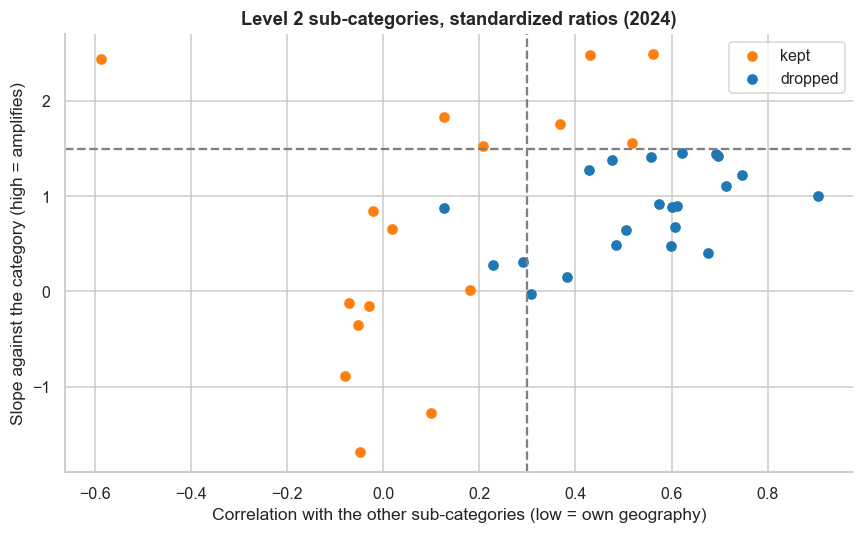

In [154]:
# the same two measures on one chart: the dashed lines are the two thresholds
plt.figure(figsize=(8, 5))
for kept, color in [(True, "tab:orange"), (False, "tab:blue")]:
    part = measures[measures["adds_information"] == kept]
    plt.scatter(part["geo_sisters"], part["slope"], color=color, label="kept" if kept else "dropped")
plt.axvline(0.3, color="grey", linestyle="--")
plt.axhline(1.5, color="grey", linestyle="--")
plt.xlabel("Correlation with the other sub-categories (low = own geography)")
plt.ylabel("Slope against the category (high = amplifies)")
plt.title(f"Level 2 sub-categories, standardized ratios ({last_year})")
plt.legend()
plt.tight_layout()
plt.show()

As mentioned we kept sub-categories that amplify the category's regional gap and have a specific pattern. All the orange points are on the left or on the top of the dotted lines with some marginal mistakes. 

#### *Does level 3 bring information ?*
The standardized ratio was only done for level 1 and 2. We do not have enough patients by age range for this level to do a standardization. So, here we only perform the geographic analysis since the amplification analysis would be biased.

In [125]:
# prepare raw prevalence ratios for level 3 pathologies across regions
deep = df[df["geo_level"].isin(["France", "Region"]) & (df["age_gp"] == "All") & (df["sex"] == 9)
          & df["is_patho"] & (df["year"] == last_year)]
nat_deep = deep[deep["geo_level"] == "France"].set_index("patho_code")["prev"]
reg_deep = deep[deep["geo_level"] == "Region"].pivot_table(index="region", columns="patho_code", values="prev")
deep_table = reg_deep.div(nat_deep.reindex(reg_deep.columns), axis=1)

rows = []
# Iterate through level 2 parents to analyze their level 3 children
for parent in codes[codes["level"] == 2].itertuples():
    children = codes.loc[(codes["level"] == 3) & (codes["patho_l1"] == parent.patho_l1)
                         & (codes["patho_l2"] == parent.patho_l2), "patho_code"]
    children = [code for code in children if code in deep_table.columns]
    # Skip if there aren't enough sibling sub-categories to compare
    if len(children) < 2: 
        continue
    # Compute regional ranks for the level 3 children
    ranks = deep_table[children].rank()
    for child in children:
        sisters = [code for code in children if code != child]
        rows.append({
            "parent": parent.patho_l2,
            "sub_category": codes.loc[codes["patho_code"] == child, "patho_label"].iloc[0],
            "geo_sisters": ranks[child].corr(ranks[sisters].mean(axis=1)),
        })

# Evaluate how many level 3 sub-categories show a unique geographic pattern
level3 = pd.DataFrame(rows)
print(f"level 3 sub-categories with their own geography (below 0.3): "
      f"{(level3['geo_sisters'] < 0.3).sum()} / {len(level3)}")
display(level3.sort_values("geo_sisters").round(2).head(8))

level 3 sub-categories with their own geography (below 0.3): 0 / 23


,parent,sub_category,geo_sisters
10,Maladies rares,Mucoviscidose,0.41
11,Maladies rares,Hémophilie ou troubles de l'hémostase graves,0.55
12,Maladies rares,Maladies métaboliques héréditaires ou amylose,0.60
8,Maladies inflammatoires chroniques,Autres maladies inflammatoires chroniques,0.61
9,Maladies inflammatoires chroniques,Maladies inflammatoires chroniques intestinales,0.67
20,Cancer colorectal,Cancer colorectal actif,0.72
19,Cancer colorectal,Cancer colorectal sous surveillance,0.72
7,Maladies inflammatoires chroniques,Spondylarthrite ankylosante ou maladies appare...,0.75


Level 3 won't be useful for next steps of the analysis. Almost every detail ranks the regions exactly like other sub-categories of the same category of level 1, so it won't add any information. 

**What do we keep ? -> Level 1 is the default and we kept 16 sub-categories from level 2.**

In [126]:
# saved for the dashboard: it gives the level 2 sub-categories kept here
measures.to_csv("../processing/measures.csv", index=False)
print("../processing/measures.csv written", measures.shape)

processing/measures.csv written (38, 8)


### 6. Are the territorial gaps widening?

The five overseas regions are read together: their patients and their expected patients are added, then divided, so the large regions weigh more than the small ones. A category is left out for a year when fewer than four of the five regions have a usable value.

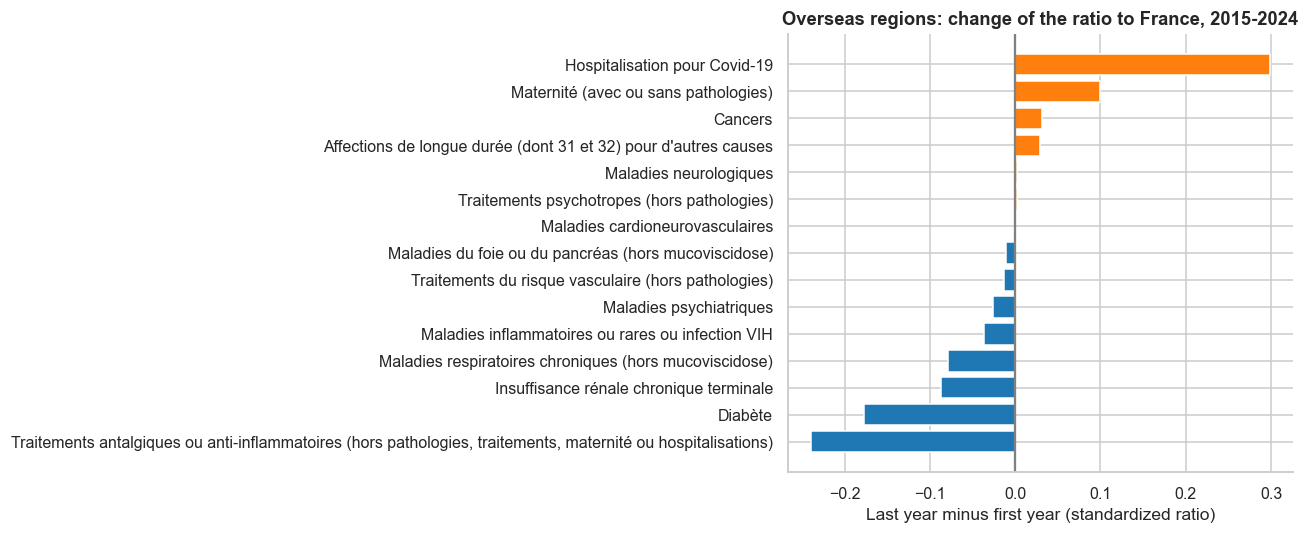

In [152]:
# the five overseas regions read together: their patients and their expected patients are
# added, then divided, so we keep proportions for small and large regions
overseas_std = std[std["region"] < 10].merge(codes[["patho_code", "patho_label", "level"]], on="patho_code")
overseas_std = overseas_std[overseas_std["level"] == 1].dropna(subset=["std_ratio"])

pooled = overseas_std.groupby(["patho_label", "year"]).agg(
    observed=("observed", "sum"), expected=("expected", "sum"), n_regions=("region", "nunique"))
pooled["ratio"] = pooled["observed"] / pooled["expected"]
pooled.loc[pooled["n_regions"] < 3, "ratio"] = float("nan")   # at least 3 of the 5 regions
pooled = pooled["ratio"].unstack()

# last year with a value minus first year with a value, for each category
change = pooled.apply(lambda row: row.dropna().iloc[-1] - row.dropna().iloc[0], axis=1).sort_values()

plt.figure(figsize=(12, 5))
plt.barh(change.index, change.values,
         color=["tab:orange" if value >= 0 else "tab:blue" for value in change])
plt.axvline(0, color="grey")
plt.xlabel("Last year minus first year (standardized ratio)")
plt.title(f"Overseas regions: change of the ratio to France, {first_year}-{last_year}")
plt.tight_layout()
plt.show()

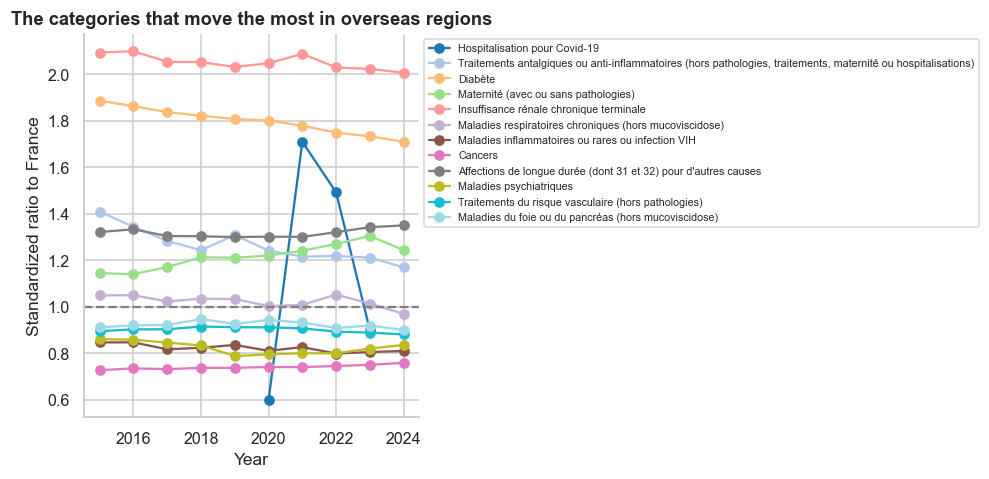

In [156]:
# the 10 categories that move the most, year by year
moving = change.abs().sort_values(ascending=False).head(12).index
pooled.columns.name = None

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = plt.cm.tab20(np.linspace(0, 1, len(moving))) # to avoid same colors for different legends

pooled.loc[moving].T.plot(ax=ax, marker="o", color=colors)
plt.axhline(1, color="grey", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Standardized ratio to France")
plt.title("The categories that move the most in overseas regions")
plt.legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

The gaps are **stable, not widening**. The bar plot shows minor change about +/-0.2.
There are two types of main changes:
- slow convergence toward national mean: there is a slow convergence of painkiller treatments, kidney issues, as well as a decrease in diabetes.
- exceptional events: the biggest change is related to Covid-19 hospitalisations as expected.

If a gap persists for ten years, it is not a marginal variation or a temporary year effect, but a structural fact. Looking at the 10-year trajectory allows to separate noise from permanent health disparities. It confirms that major excess rates remain constant over time while others steadily converge toward national standards.

### 7. Diseases, treatments and hospitalisations: three readings of the same territory

- an identified disease needs a recorded diagnosis
- a treatment-only (don't take disease into account) category needs a prescription without any identified disease

> Disease and treatment categories are both derived from recorded care and may overlap in how they are identified (CNAM algorithm).

Comparing them can add a layer to describe the territory.

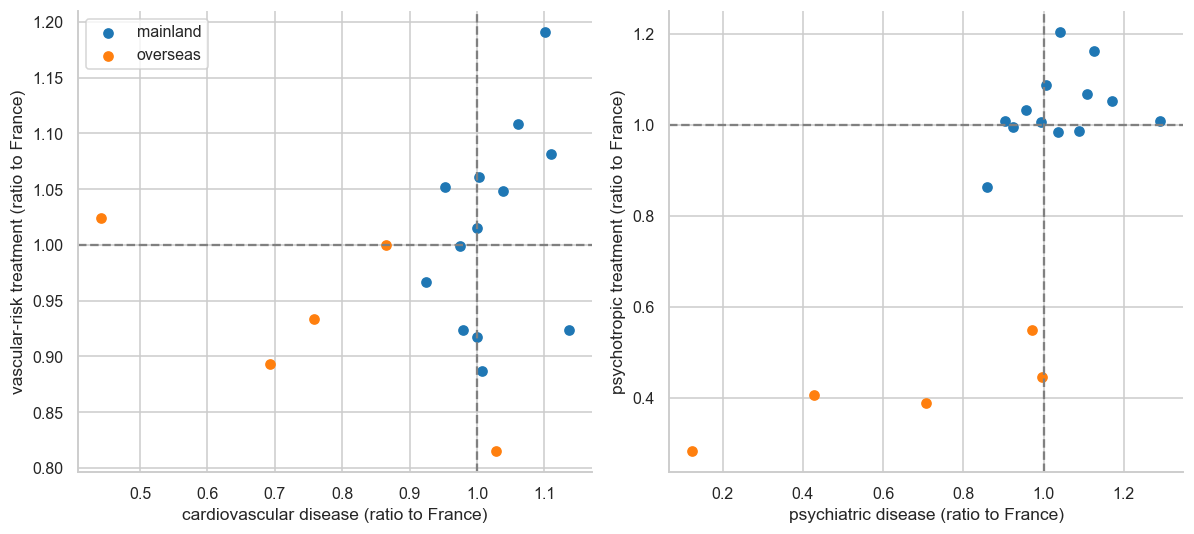

In [102]:
# one point per region: the disease on x, the treatment recorded without disease on y
pairs = {"MCV_CAT_CAT": "cardiovascular disease", "TFC_CAT_EXC": "vascular-risk treatment",
         "PSY_CAT_CAT": "psychiatric disease", "TPS_CAT_EXC": "psychotropic treatment"}

wide = std[(std["year"] == last_year) & std["patho_code"].isin(pairs)]
wide = wide.pivot_table(index="region", columns="patho_code", values="std_ratio").rename(columns=pairs)
wide["area"] = ["overseas" if code < 10 else "mainland" for code in wide.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (disease, treatment) in zip(axes, [("cardiovascular disease", "vascular-risk treatment"),
                                           ("psychiatric disease", "psychotropic treatment")]):
    for area, color in [("mainland", "tab:blue"), ("overseas", "tab:orange")]:
        part = wide[wide["area"] == area]
        ax.scatter(part[disease], part[treatment], color=color, label=area)
    ax.axvline(1, color="grey", linestyle="--")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_xlabel(f"{disease} (ratio to France)")
    ax.set_ylabel(f"{treatment} (ratio to France)")
axes[0].legend()
plt.tight_layout()
plt.show()

Overseas territories appear to have lower diagnosis rates and lower use of reimbursed treatments for cardiovascular and psychiatric diseases compared to the mainland. We must keep in mind that diagnoses in this dataset are partly inferred by the CNAM mapping algorithm. However, this raises a key question: can the algorithm itself generate such a pattern?

Maybe, because the algorithm may rely on treatment reimbursements to identify pathologies, structural barriers to healthcare in overseas regions (such as medical deserts or lower treatment dispensation) could reduce the algorithm's ability to detect diseases. As a result, lower treatment rates could artificially depress the calculated prevalence, creating a self-reinforcing pattern of under-detection.

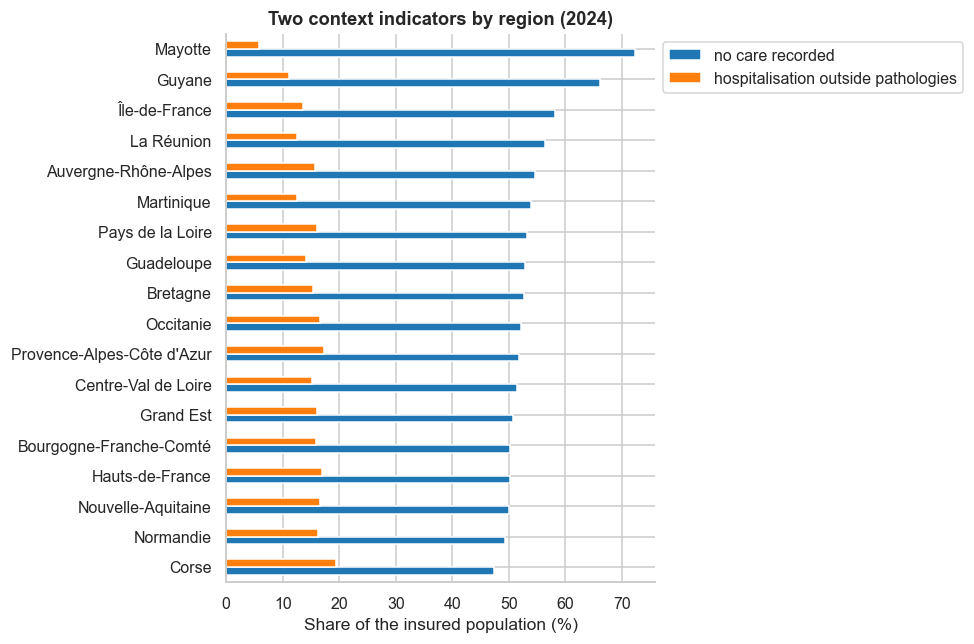

          no care recorded  hospitalisation outside pathologies
area                                                           
mainland              51.7                                 16.2
overseas              60.3                                 11.2


In [157]:
# two codes that are not pathologies, kept aside until now by "is_patho" tag
labels = {"POP_TOT_ABS": "no care recorded", "HHP_CAT_INC": "hospitalisation outside pathologies"}
context = df[(df["geo_level"] == "Region") & (df["age_gp"] == "All") & (df["sex"] == 9)
             & (df["year"] == last_year) & df["patho_code"].isin(labels)]
context = context.pivot_table(index="region", columns="patho_code", values="prev").rename(columns=labels)
context.columns.name = None
context["area"] = ["overseas" if code < 10 else "mainland" for code in context.index]
context.index = context.index.map(region_names)

context.sort_values("no care recorded")[list(labels.values())].plot(
    kind="barh", figsize=(9, 6), color=["tab:blue", "tab:orange"])
plt.xlabel("Share of the insured population (%)")
plt.ylabel("")
plt.title(f"Two context indicators by region ({last_year})")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

print(context.groupby("area")[list(labels.values())].mean().round(1).to_string())

This plot highlights key disparities in recorded care across French regions. 
- In overseas territories such as Mayotte and French Guiana, over 60% of the insured population had no recorded medical care in 2024. On average, 60.3% of people in overseas territories have no care recorded, compared to 51.7% in mainland France.
- Conversely, hospitalizations outside tracked chronic pathologies remain lower in overseas regions (11.2%) than in the mainland (16.2%).

Rather than reflecting a healthier population, these structural gaps could be linked to unequal healthcare access and structural barriers between overseas territories and mainland France. (we will analyse each year on the dashboard)

### Analysis conclusion

*What to take away ?*

* **Age repartition matters**: raw prevalence partly reflects population structure. Age standardization, using the observed-to-expected patient ratio, reveals differences hidden by this effect.
* **Overseas regions differ**: they do not form one homogeneous group. Most gaps examined remain stable over time, although some narrow.
* **Detail from sub-category of disease must add information**: retain level 1 for the overview and 16 level 2 subcategories for distinct geographic patterns or stronger territorial contrasts. Selection thresholds are exploratory choices, not statistical tests.
* **Level 3 has limited value here**: it adds little geographic information in the comparisons performed. Insufficient age-specific counts also prevent standardization.
* **Recorded prevalence is not the only variable adding information about disease**: lower diagnosis and treatment rates may reflect barriers to care or under-detection. The analysis cannot establish their causes.